# code_221 · Observe inputs now and evaluate outcomes only when mature

**Book:** section 42.1. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_42_GUIDE.md), [execution evidence](../CHAPTER_42_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_221).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Monitoring separates observable inputs, historical predictions, delayed outcome maturity, selection mechanisms, operational versions and authority to update. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8021;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8021


## Keep serving health, coverage and predictive evidence on separate clocks
 Fit a logistic model on1,000 generated source observations. Create120 days of50 independent requests; the response law changes on day65 while input distributions remain stable. Missing load probability increases from0.02 to0.18 after day40; missing records are invalid, and an independently generated one-percent timeout fixture returns deferred. Generated exponential latencies are scenario values, not measured service timing. Preserve every eligible request's day, raw features, disposition and original prediction. Labels concern a seven-day outcome window and arrive three additional days after positive outcomes or seven after negative outcomes. At as-of day80, only prediction cohorts at least14 days old are mature. No unknown or pending outcome is filled with zero.


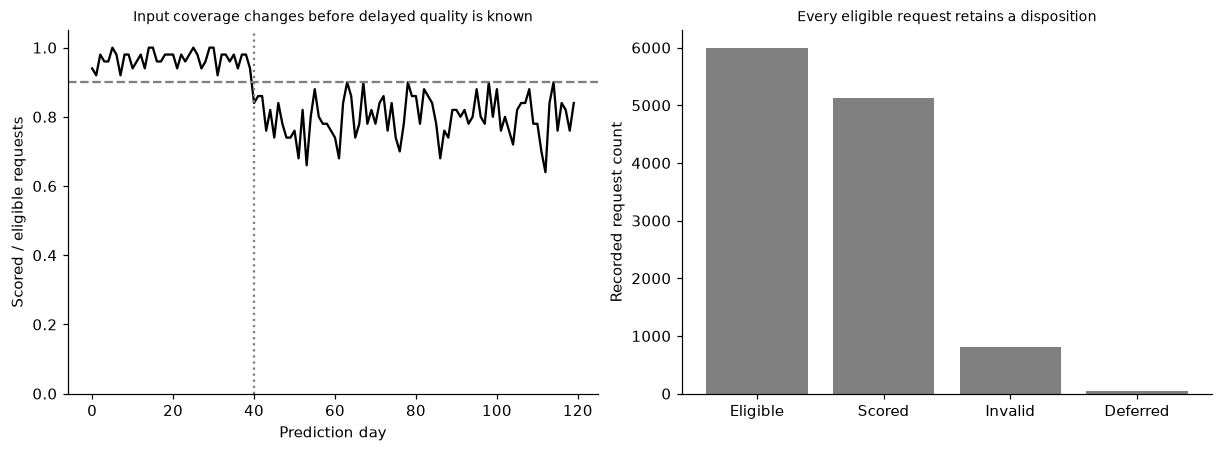

In [2]:
from sklearn.linear_model import LogisticRegression
xs=rng.normal(size=(1000,2));ys=rng.binomial(1,expit(xs[:,0]-.6*xs[:,1]));model=LogisticRegression(C=1).fit(xs,ys);day=np.repeat(np.arange(120),50);x=rng.normal(size=(6000,2));truth=rng.binomial(1,expit(np.where(day>=65,-1.,1.)*x[:,0]-.6*x[:,1]));missing=rng.random(6000)<np.where(day>=40,.18,.02);timeout=(rng.random(6000)<.01)&~missing;valid=~missing&~timeout;status=np.where(missing,'invalid',np.where(timeout,'deferred','scored'));p=np.full(6000,np.nan);p[valid]=model.predict_proba(x[valid])[:,1];arrival=day+7+np.where(truth==1,3,7);ledger=pd.DataFrame({'request_id':np.arange(6000),'prediction_day':day,'status':status,'probability':p,'label_arrival_day':arrival,'scenario_latency_ms':rng.exponential(3,6000)});asof=80;visible=valid&(arrival<=asof);mature=valid&(day<=asof-14);assert np.all(arrival[mature]<=asof);assert not np.any(np.isfinite(p[~valid]));assert np.all(day[visible]<asof);daily=ledger.groupby('prediction_day').agg(eligible=('request_id','size'),scored=('probability','count'),scenario_latency_p95=('scenario_latency_ms',lambda z:np.quantile(z,.95)));daily['score_coverage']=daily.scored/daily.eligible;spec={'input_coverage':{'owner':'fictional data steward','cadence':'daily','trigger':'coverage below 0.9','response':'investigate channel and report invalid count'},'serving':{'owner':'fictional operations owner','cadence':'daily','trigger':'timeout fraction above 0.02','response':'inspect serving path; preserve dispositions'},'quality':{'owner':'fictional model owner','cadence':'weekly mature cohorts','trigger':'mature Brier above 0.27','response':'investigate; no automatic replacement'}};RESULTS.update(source_rows=1000,eligible_requests=6000,scored_requests=int(valid.sum()),invalid_requests=int(missing.sum()),deferred_requests=int(timeout.sum()),asof_day=80,visible_labels=int(visible.sum()),mature_scored_labels=int(mature.sum()),pending_outcomes_are_zero=False,monitoring_specification=spec,latencies_are_generated_scenario_values=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(daily.index,daily.score_coverage,color='black');axes[0].axhline(.9,color='.5',linestyle='--');axes[0].axvline(40,color='.5',linestyle=':');axes[0].set(xlabel='Prediction day',ylabel='Scored / eligible requests',ylim=(0,1.05),title='Input coverage changes before delayed quality is known');axes[1].bar(['Eligible','Scored','Invalid','Deferred'],[6000,int(valid.sum()),int(missing.sum()),int(timeout.sum())],color='.5');axes[1].set(ylabel='Recorded request count',title='Every eligible request retains a disposition');plt.show()


## Join outcomes as of the review date and retain immature bias
 Compare recent prediction cohorts on days67–73: by day80 positives arrive before negatives, so observed-label-only performance is not a mature-cohort estimate. Compute the visible subset and privileged complete simulator cohort separately, keeping counts. Mature weekly scores use original saved probabilities, with a declared fourteen-day horizon and no reconstruction from a later fitted model. VisualA shows prediction/input validation, scenario action, true outcome-window end, label arrival and maturity for two records. Truth before arrival is displayed solely to explain the generated timeline; ordinary monitoring never reads it. Fixture owners and thresholds are an executable monitoring specification, not real organizational approvals.


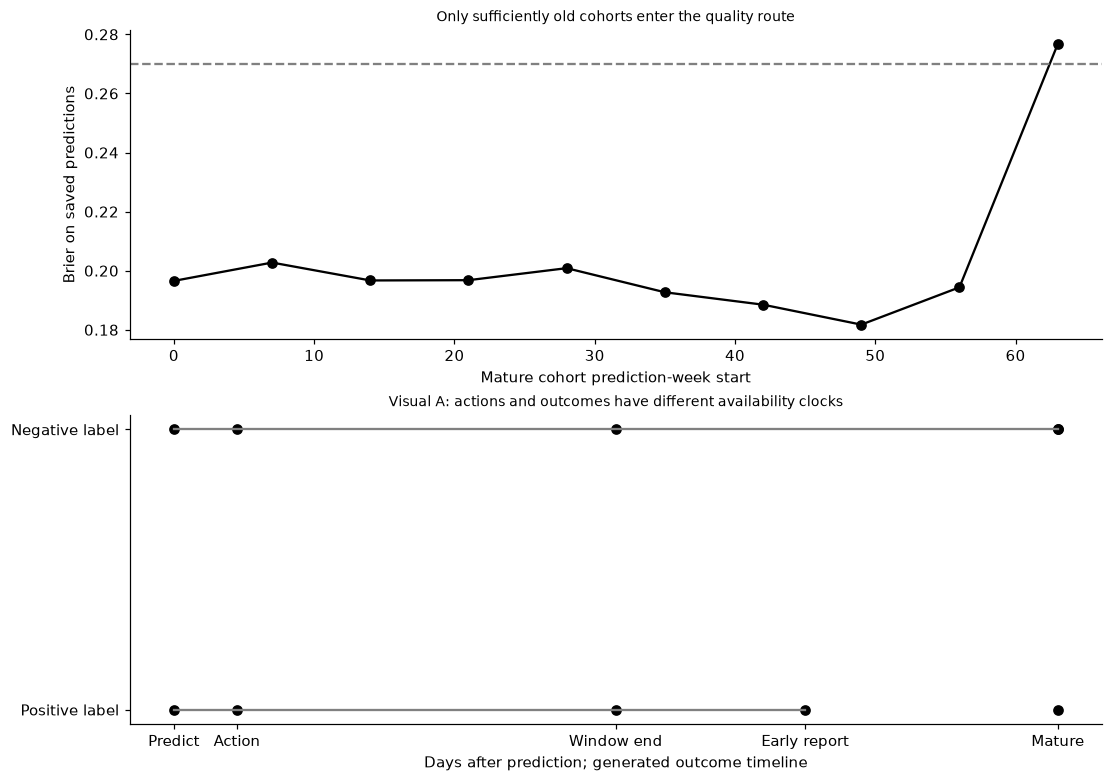

In [3]:
recent=valid&(day>=67)&(day<=73);recent_seen=recent&(arrival<=asof);assert recent_seen.sum()>0 and recent_seen.sum()<recent.sum();brier=lambda mask:float(np.mean((p[mask]-truth[mask])**2));mature_scores=[]
for start in range(0,67,7):
    mask=mature&(day>=start)&(day<start+7)
    if mask.sum():mature_scores.append({'prediction_start_day':start,'n':int(mask.sum()),'Brier':brier(mask)})
original=p.copy();assert np.array_equal(original[valid],model.predict_proba(x[valid])[:,1]);RESULTS.update(recent_cohort_scored=int(recent.sum()),recent_cohort_visible=int(recent_seen.sum()),recent_visible_positive_fraction=float(truth[recent_seen].mean()),recent_full_simulator_positive_fraction=float(truth[recent].mean()),recent_visible_Brier=brier(recent_seen),recent_complete_privileged_Brier=brier(recent),mature_cohort_scores=mature_scores,historical_probabilities_preserved=True);fig,axes=plt.subplots(2,1,figsize=(10,7));axes[0].plot([r['prediction_start_day'] for r in mature_scores],[r['Brier'] for r in mature_scores],'o-',color='black');axes[0].axhline(.27,color='.5',linestyle='--');axes[0].set(xlabel='Mature cohort prediction-week start',ylabel='Brier on saved predictions',title='Only sufficiently old cohorts enter the quality route')
for j,(label,delay) in enumerate([('Positive outcome',10),('Negative outcome',14)]):
    axes[1].plot([0,delay],[j,j],color='.5');axes[1].scatter([0,1,7,delay,14],[j]*5,marker='o',color='black');
axes[1].set(yticks=[0,1],yticklabels=['Positive label','Negative label'],xticks=[0,1,7,10,14],xticklabels=['Predict','Action','Window end','Early report','Mature'],xlabel='Days after prediction; generated outcome timeline',title='Visual A: actions and outcomes have different availability clocks');plt.show()


In [4]:
summary={'example_id':'code_221','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual request ledger with invalid deferred scored denominators and daily input-health summaries', 'as-of delayed-label joins retaining original prediction-time probabilities', 'fixed maturity horizon separated from label-dependent early arrivals and privileged full truth', 'delayed-outcome monitoring-loop visual with explicit fictional owners and response thresholds'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual request ledger with invalid deferred scored denominators and daily input-health summaries", "as-of delayed-label joins retaining original prediction-time probabilities", "fixed maturity horizon separated from label-dependent early arrivals and privileged full truth", "delayed-outcome monitoring-loop visual with explicit fictional owners and response thresholds"], "elapsed_seconds": 0.286, "example_id": "code_221", "hardware": "Darwin arm64 CPU", "results": {"asof_day": 80, "deferred_requests": 54, "eligible_requests": 6000, "historical_probabilities_preserved": true, "invalid_requests": 814, "latencies_are_generated_scenario_values": true, "mature_cohort_scores": [{"Brier": 0.19655221302726458, "n": 337, "prediction_start_day": 0}, {"Brier": 0.2027564007441759, "n": 335, "prediction_start_day": 7}, {"Brier": 0.1967051891825766, "n": 343, "prediction_start_day": 14}, {"Brier": 0.19679582307797183, "n": 339, "prediction_start_day"